In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
print("Everything is installed")

Everything is installed


In [2]:
df = fetch_openml(data_id=41214, as_frame=True).frame

print(df.shape)
df.head()

(678013, 12)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,3.0,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,5.0,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,10.0,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,11.0,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


In [3]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   IDpol       678013 non-null  float64 
 1   ClaimNb     678013 non-null  int64   
 2   Exposure    678013 non-null  float64 
 3   Area        678013 non-null  category
 4   VehPower    678013 non-null  int64   
 5   VehAge      678013 non-null  int64   
 6   DrivAge     678013 non-null  int64   
 7   BonusMalus  678013 non-null  int64   
 8   VehBrand    678013 non-null  category
 9   VehGas      678013 non-null  str     
 10  Density     678013 non-null  int64   
 11  Region      678013 non-null  category
dtypes: category(3), float64(2), int64(6), str(1)
memory usage: 48.5 MB


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
count,6.780130e+05,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000
mean,2.621857e+06,0.053247,0.528750,6.454631,7.044265,45.499122,59.761502,1792.422405
std,1.641783e+06,0.240117,0.364442,2.050906,5.666232,14.137444,15.636658,3958.646564
min,1.000000e+00,0.000000,0.002732,4.000000,0.000000,18.000000,50.000000,1.000000
25%,1.157951e+06,0.000000,0.180000,5.000000,2.000000,34.000000,50.000000,92.000000
50%,2.272152e+06,0.000000,0.490000,6.000000,6.000000,44.000000,50.000000,393.000000
75%,4.046274e+06,0.000000,0.990000,7.000000,11.000000,55.000000,64.000000,1658.000000
max,6.114330e+06,16.000000,2.010000,15.000000,100.000000,100.000000,230.000000,27000.000000


In [4]:
# 1. Cap exposure at 1 year
df["Exposure"] = df["Exposure"].clip(upper=1)

# 2. Group driver ages into bands
df["AgeBand"] = pd.cut(
    df["DrivAge"],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"],
)

# 3. Overall claim frequency
overall = df["ClaimNb"].sum() / df["Exposure"].sum()
print("Total claims:", df["ClaimNb"].sum())
print("Total exposure (years):", round(df["Exposure"].sum()))
print("Overall claim frequency:", round(overall, 4))
print("Policies with no age band:", df["AgeBand"].isna().sum())

Total claims: 36102
Total exposure (years): 358360
Overall claim frequency: 0.1007
Policies with no age band: 0


In [5]:
def freq_by(col):
    g = df.groupby(col, observed=True).agg(
        policies=("IDpol", "count"),
        claims=("ClaimNb", "sum"),
        exposure=("Exposure", "sum"),
    )
    g["frequency"] = g["claims"] / g["exposure"]
    g["relativity"] = g["frequency"] / overall
    return g.round(4)

print("By driver age band")
display(freq_by("AgeBand"))

print("By fuel type")
display(freq_by("VehGas"))

print("By area")
display(freq_by("Area"))

By driver age band


,policies,claims,exposure,frequency,relativity
AgeBand,,,,,
18-25,38895,2841,16227.1933,0.1751,1.7379
26-35,149183,6662,69238.0081,0.0962,0.9551
36-45,170352,8397,87659.3963,0.0958,0.9509
46-55,161899,9256,89231.8264,0.1037,1.0297
56-65,90691,4748,51758.0933,0.0917,0.9106
66+,66993,4198,44245.5882,0.0949,0.9418


By fuel type


,policies,claims,exposure,frequency,relativity
VehGas,,,,,
'Diesel',332136,16648,170587.5531,0.0976,0.9687
'Regular',345877,19454,187772.5523,0.1036,1.0284


By area


,policies,claims,exposure,frequency,relativity
Area,,,,,
A,103957,5063,61956.8277,0.0817,0.8112
B,75459,3800,43001.8239,0.0884,0.8772
C,191880,9875,104402.5238,0.0946,0.9389
D,151596,8428,77087.8017,0.1093,1.0852
E,137167,7805,63785.6943,0.1224,1.2146
F,17954,1131,8125.4341,0.1392,1.3817


In [6]:
df["VehGas"] = df["VehGas"].str.strip("'")
freq_by("VehGas")

,policies,claims,exposure,frequency,relativity
VehGas,,,,,
Diesel,332136,16648,170587.5531,0.0976,0.9687
Regular,345877,19454,187772.5523,0.1036,1.0284


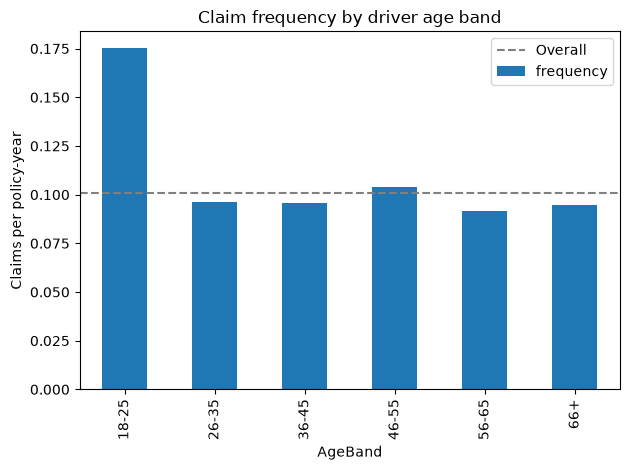

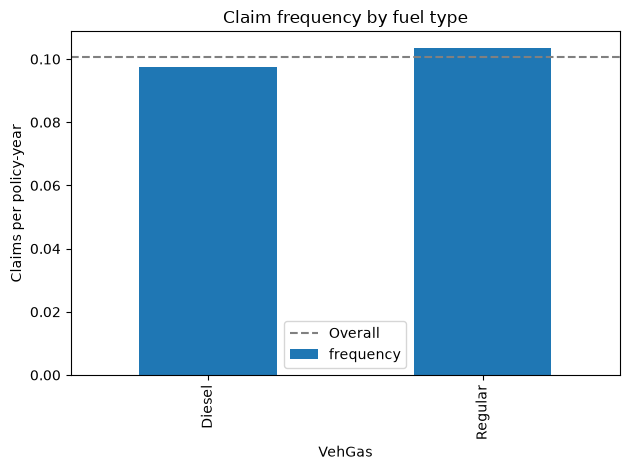

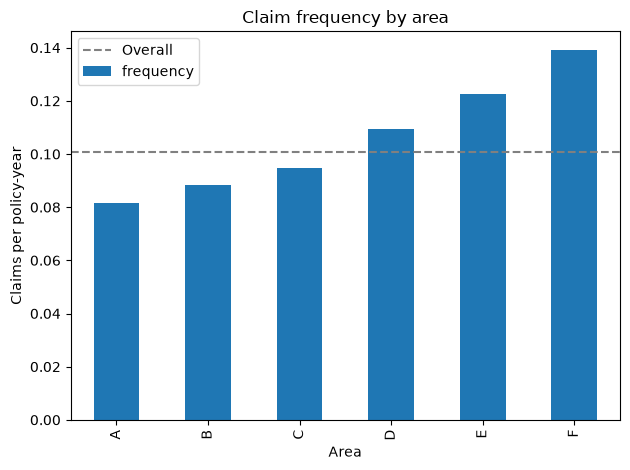

In [7]:
for col, title in [("AgeBand", "driver age band"), ("VehGas", "fuel type"), ("Area", "area")]:
    freq_by(col)["frequency"].plot(kind="bar")
    plt.axhline(overall, color="grey", linestyle="--", label="Overall")
    plt.title(f"Claim frequency by {title}")
    plt.ylabel("Claims per policy-year")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{col}_frequency.png")
    plt.show()